<a href="https://colab.research.google.com/github/jinatyeasmin/MCA-DATA-SCIENCE/blob/main/Match-results/Batting_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Data Cleaning

In [5]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

df = pd.read_csv('/content/drive/MyDrive/ML/Batting.csv')
print(df.shape)
df.head()

(745, 13)


,Date,Team,Vs,Player,Dismissal,R,B,M,4s,6s,SR,Chase,Win
0,7.2.26,Netherland,Pakistan,Michael Levitt,c Afridi b Nawaz,24,15,23,3,1,160.00,0,0
1,7.2.26,Netherland,Pakistan,Max O'Dowd,c ?Usman b Mirza,5,7,16,1,0,71.42,0,0
2,7.2.26,Netherland,Pakistan,Bas de Leede,c Babar b Nawaz,30,25,42,4,0,120.00,0,0
3,7.2.26,Netherland,Pakistan,Colin Ackermann,b Abrar Ahmed,20,14,16,4,0,142.85,0,0
4,7.2.26,Netherland,Pakistan,Scott Edwards (c)?,c Farhan b Abrar,37,29,32,3,1,127.58,0,0


In [6]:

print(df.isna().sum().sum(), 'missing values |', df.duplicated().sum(), 'duplicate rows')
print('Team spellings found:', sorted(df['Team'].map(repr).unique()))

0 missing values | 0 duplicate rows
Team spellings found: ["'Afganisthan'", "'Australia'", "'Canada'", "'ENG'", "'England'", "'India'", "'Ireland'", "'Italy'", "'Namibia'", "'Nepal'", "'Netherland'", "'New Zealand '", "'New Zealand'", "'New zealand'", "'Oman'", "'Pakistan'", "'Scotland'", "'South Africa'", "'Sri Lanka '", "'Sri Lanka'", "'UAE'", "'USA'", "'West Indies'", "'Zimbabwae'", "'Zimbabwe'"]


In [7]:
#Teams
team_fix = {'Afganisthan':'Afghanistan', 'Afganistan':'Afghanistan', 'ENG':'England',
            'Netherland':'Netherlands', 'Zimbabwae':'Zimbabwe', 'Zimbawe':'Zimbabwe',
            'New zealand':'New Zealand'}
for c in ['Team', 'Vs']:
    df[c] = df[c].str.strip().replace(team_fix)

#Dates (day.month.year)
df['Date'] = pd.to_datetime(df['Date'], format='%d.%m.%y')

#Player names and dismissal text
def fix_text(s):
    return s.replace('India', 'ind').replace('Canada', 'can')
df['Player'] = (df['Player'].map(fix_text)
                .str.replace(r'\(c\)|\?|†', '', regex=True)
                .str.replace(r'\s+', ' ', regex=True).str.strip())
df['Dismissal'] = df['Dismissal'].map(fix_text).str.strip()

#Same player, different spelling
alias = {'Azmat Omarzai':'Azmatullah Omarzai', 'Gian Meade':'Gian-Piero Meade', 'G. Meade':'Gian-Piero Meade',
         'Salman Agha':'Salman Ali Agha', 'C. Kalugamage':'Crishan Kalugamage',
         'D. Singh Airee':'Dipendra Singh Airee', 'J. Loftie-Eaton':'Jan Nicol Loftie-Eaton',
         'M. Nadeem':'Mohammad Nadeem', 'M. Theekshana':'Maheesh Theekshana', 'N. Dhaliwal':'Navneet Dhaliwal',
         'R. Gurbaz':'Rahmanullah Gurbaz', 'R. Trumpelmann':'Ruben Trumpelmann', 'S. Rutherford':'Sherfane Rutherford',
         'Shaheen Afridi':'Shaheen Shah Afridi', 'T. Marumani':'Tadiwanashe Marumani', 'T. Musekiwa':'Tashinga Musekiwa',
         'Varun Chakaravarthy':'Varun Chakravarthy', 'Aarif Sheikh':'Aasif Sheikh', 'Gulsan Jha':'Gulshan Jha'}
df['Player'] = df['Player'].replace(alias)


df['Out'] = (~df['Dismissal'].str.contains('not out|retired hurt', regex=True)).astype(int)
df['match_id'] = df['Date'].dt.strftime('%Y-%m-%d') + ' ' + df.apply(lambda r: ' v '.join(sorted([r['Team'], r['Vs']])), axis=1)

# Re-calculate Strike Rate ourselves so it is always consistent
df['SR'] = np.where(df['B'] > 0, df['R'] / df['B'] * 100, 0).round(2)

print('Players:', df['Player'].nunique(), '| Teams:', df['Team'].nunique(), '| Matches:', df['match_id'].nunique())
print(sorted(df['Team'].unique()))

Players: 247 | Teams: 20 | Matches: 45
['Afghanistan', 'Australia', 'Canada', 'England', 'India', 'Ireland', 'Italy', 'Namibia', 'Nepal', 'Netherlands', 'New Zealand', 'Oman', 'Pakistan', 'Scotland', 'South Africa', 'Sri Lanka', 'UAE', 'USA', 'West Indies', 'Zimbabwe']


In [8]:
# Sanity check: every match should have 2 innings and exactly 1 winning team
innings = (df.groupby(['match_id', 'Date', 'Team', 'Vs'])
             .agg(Runs=('R', 'sum'), Chase=('Chase', 'max'), Win=('Win', 'max'), Batters=('Player', 'count'))
             .reset_index())
per_match = innings.groupby('match_id').agg(n_innings=('Team', 'count'), winners=('Win', 'sum'))
print('Matches with 2 innings   :', (per_match.n_innings == 2).sum(), 'of', len(per_match))
print('Matches with 1 winner    :', (per_match.winners == 1).sum(), 'of', len(per_match))
per_match[(per_match.n_innings != 2) | (per_match.winners != 1)]

Matches with 2 innings   : 45 of 45
Matches with 1 winner    : 45 of 45


,n_innings,winners
match_id,,


In [9]:
# Player summary table
player = (df.groupby('Player')
            .agg(Team=('Team', 'first'), Innings=('match_id', 'count'), Runs=('R', 'sum'), Balls=('B', 'sum'),
                 Fours=('4s', 'sum'), Sixes=('6s', 'sum'), Outs=('Out', 'sum')))
player['SR'] = (player['Runs'] / player['Balls'] * 100).round(2)
winner = innings[innings.Win == 1].set_index('match_id')['Team']      # match -> winning team
player.sort_values('Runs', ascending=False).head()

,Team,Innings,Runs,Balls,Fours,Sixes,Outs,SR
Player,,,,,,,,
Sahibzada Farhan,Pakistan,5,383,235,37,18,4,162.98
Brian Bennett,Zimbabwe,5,277,204,31,6,1,135.78
Suryakumar Yadav,India,6,265,175,27,13,4,151.43
Aiden Markram,South Africa,6,264,148,31,10,4,178.38
Shimron Hetmyer,West Indies,6,221,121,15,17,5,182.64


## Q1. Top 10 batsmen by total runs

,Team,Innings,Runs,Balls,SR
Player,,,,,
Sahibzada Farhan,Pakistan,5,383,235,162.98
Brian Bennett,Zimbabwe,5,277,204,135.78
Suryakumar Yadav,India,6,265,175,151.43
Aiden Markram,South Africa,6,264,148,178.38
Shimron Hetmyer,West Indies,6,221,121,182.64
Tim Seifert,New Zealand,6,216,137,157.66
Pathum Nissanka,Sri Lanka,6,207,135,153.33
Pavan Rathnayake,Sri Lanka,6,205,132,155.30
Ryan Rickelton,South Africa,6,197,111,177.48


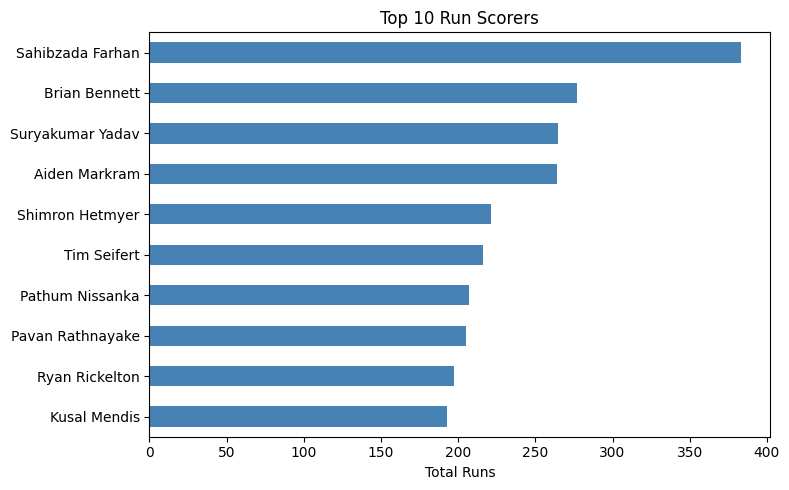

Answer: Sahibzada Farhan (Pakistan) leads with 383 runs.


In [10]:
q1 = player.sort_values('Runs', ascending=False).head(10)[['Team', 'Innings', 'Runs', 'Balls', 'SR']]
display(q1)

q1['Runs'][::-1].plot(kind='barh', figsize=(8, 5), color='steelblue')
plt.title('Top 10 Run Scorers'); plt.xlabel('Total Runs'); plt.ylabel(''); plt.tight_layout(); plt.show()
print(f"Answer: {q1.index[0]} ({q1.Team.iloc[0]}) leads with {q1.Runs.iloc[0]} runs.")

## Q2. Top 10 strike rates (minimum 50 balls faced)


,Team,Runs,Balls,SR
Player,,,,
Dasun Shanaka,Sri Lanka,135,64,210.94
Mitchell Marsh,Australia,118,60,196.67
Fakhar Zaman,Pakistan,109,58,187.93
Shimron Hetmyer,West Indies,221,121,182.64
Sherfane Rutherford,West Indies,169,93,181.72
Ben Manenti,Italy,138,77,179.22
Aiden Markram,South Africa,264,148,178.38
Shubham Ranjane,USA,178,100,178.00
Ryan Rickelton,South Africa,197,111,177.48


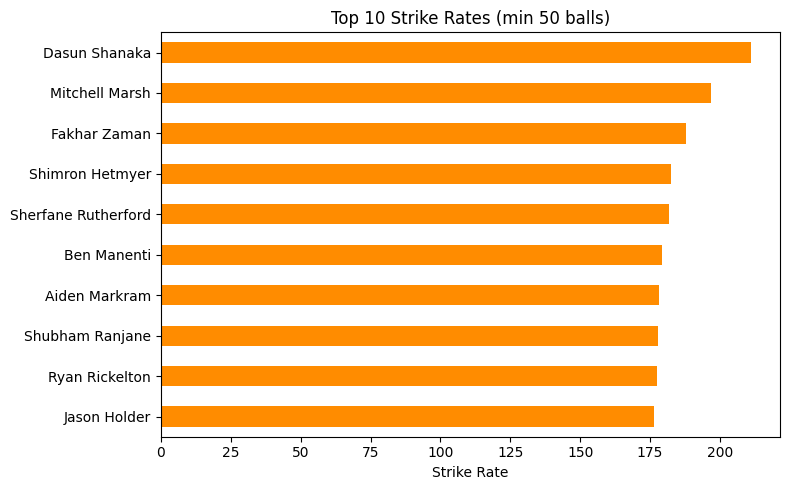

Answer: Dasun Shanaka has the best strike rate: 210.94.


In [11]:
q2 = player[player.Balls >= 50].sort_values('SR', ascending=False).head(10)[['Team', 'Runs', 'Balls', 'SR']]
display(q2)

q2['SR'][::-1].plot(kind='barh', figsize=(8, 5), color='darkorange')
plt.title('Top 10 Strike Rates (min 50 balls)'); plt.xlabel('Strike Rate'); plt.ylabel(''); plt.tight_layout(); plt.show()
print(f"Answer: {q2.index[0]} has the best strike rate: {q2.SR.iloc[0]}.")

## Q3. Most fours and most sixes

,Team,Fours
Player,,
Sahibzada Farhan,Pakistan,37
Brian Bennett,Zimbabwe,31
Aiden Markram,South Africa,31
Suryakumar Yadav,India,27
Tim Seifert,New Zealand,25


,Team,Sixes
Player,,
Sahibzada Farhan,Pakistan,18
Shimron Hetmyer,West Indies,17
Dasun Shanaka,Sri Lanka,13
Suryakumar Yadav,India,13
Sherfane Rutherford,West Indies,12


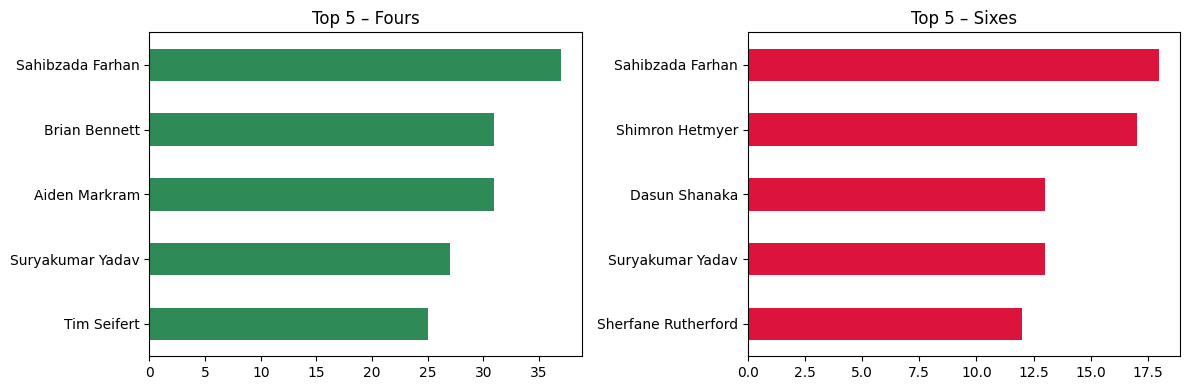

Answer: Most fours = ['Sahibzada Farhan'] (37); most sixes = ['Sahibzada Farhan'] (18).


In [12]:
fours = player.sort_values('Fours', ascending=False).head(5)[['Team', 'Fours']]
sixes = player.sort_values('Sixes', ascending=False).head(5)[['Team', 'Sixes']]
display(fours); display(sixes)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fours['Fours'][::-1].plot(kind='barh', ax=ax[0], color='seagreen', title='Top 5 – Fours')
sixes['Sixes'][::-1].plot(kind='barh', ax=ax[1], color='crimson', title='Top 5 – Sixes')
for a in ax: a.set_ylabel('')
plt.tight_layout(); plt.show()

top4 = player[player.Fours == player.Fours.max()].index.tolist()
top6 = player[player.Sixes == player.Sixes.max()].index.tolist()
print(f"Answer: Most fours = {top4} ({player.Fours.max()}); most sixes = {top6} ({player.Sixes.max()}).")

## Q4. Team with the most match wins

,Wins
Team,
South Africa,6
India,5
West Indies,5
England,4
New Zealand,4
Pakistan,4
Sri Lanka,3
Zimbabwe,3
Australia,2


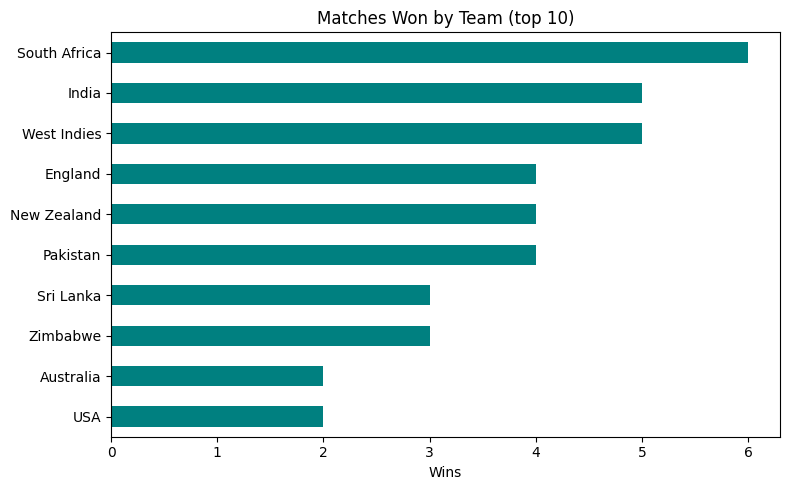

Answer: South Africa – 6 wins.


In [13]:
wins = innings[innings.Win == 1].groupby('Team').size().sort_values(ascending=False)
display(wins.to_frame('Wins').head(10))

wins.head(10)[::-1].plot(kind='barh', figsize=(8, 5), color='teal')
plt.title('Matches Won by Team (top 10)'); plt.xlabel('Wins'); plt.ylabel(''); plt.tight_layout(); plt.show()
best = wins[wins == wins.max()]
print(f"Answer: {', '.join(best.index)} – {best.iloc[0]} wins.")

## Q5. Highest run scorer in every match

In [14]:
idx = df.groupby('match_id')['R'].transform('max') == df['R']          # keeps ties
q5 = (df[idx][['Date', 'Player', 'Team', 'Vs', 'R']]
        .rename(columns={'Vs': 'Opponent', 'R': 'Runs Scored'})
        .sort_values(['Date', 'Runs Scored'], ascending=[True, False]).reset_index(drop=True))
q5['Date'] = q5['Date'].dt.date
print(len(q5), 'rows for', df.match_id.nunique(), 'matches (a row is repeated only if two batters tied)')
q5

45 rows for 45 matches (a row is repeated only if two batters tied)


,Date,Player,Team,Opponent,Runs Scored
0,2026-02-07,Suryakumar Yadav,India,USA,84
1,2026-02-07,Shimron Hetmyer,West Indies,Scotland,64
2,2026-02-07,Sahibzada Farhan,Pakistan,Netherlands,47
3,2026-02-08,Tim Seifert,New Zealand,Afghanistan,65
4,2026-02-08,Kusal Mendis,Sri Lanka,Ireland,56
5,2026-02-09,George Munsey,Scotland,Italy,84
6,2026-02-09,Navneet Dhaliwal,Canada,South Africa,64
7,2026-02-09,Brian Bennett,Zimbabwe,Oman,48
8,2026-02-10,Tim Seifert,New Zealand,UAE,89
9,2026-02-10,Sahibzada Farhan,Pakistan,USA,73


## Q6. Chasing vs batting first
*Assumption:* team total = sum of the batters' runs (extras are not in the file, so totals are slightly lower than the real scores). `Chase = 1` means the team batted second.

,Innings,Avg_Runs,Wins,Win %
Type,,,,
Batting first,45,166.2,22,48.9
Chasing,45,146.7,23,51.1


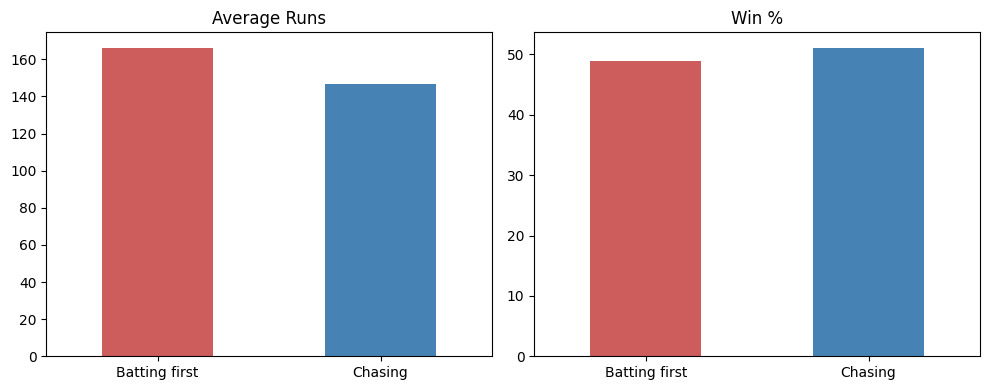

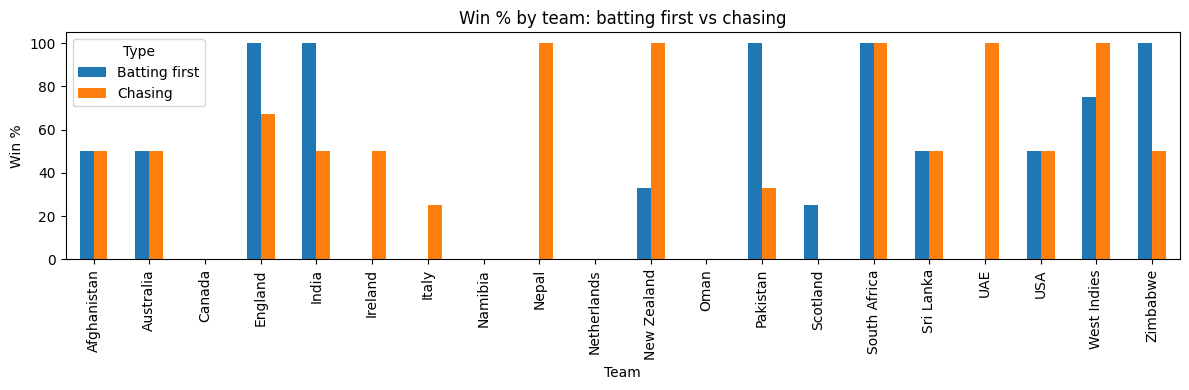

Answer: Teams win more often when chasing (51.1% wins).


In [15]:
innings['Type'] = np.where(innings.Chase == 1, 'Chasing', 'Batting first')
q6 = (innings.groupby('Type').agg(Innings=('Runs', 'count'), Avg_Runs=('Runs', 'mean'), Wins=('Win', 'sum')))
q6['Win %'] = (q6.Wins / q6.Innings * 100).round(1)
q6['Avg_Runs'] = q6.Avg_Runs.round(1)
display(q6)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
q6['Avg_Runs'].plot(kind='bar', ax=ax[0], color=['indianred', 'steelblue'], rot=0, title='Average Runs')
q6['Win %'].plot(kind='bar', ax=ax[1], color=['indianred', 'steelblue'], rot=0, title='Win %')
for a in ax: a.set_xlabel('')
plt.tight_layout(); plt.show()

# per team
by_team = innings.pivot_table(index='Team', columns='Type', values='Win', aggfunc='mean').mul(100).round(0)
by_team.plot(kind='bar', figsize=(12, 4), title='Win % by team: batting first vs chasing'); plt.ylabel('Win %'); plt.tight_layout(); plt.show()

better = q6['Win %'].idxmax()
print(f"Answer: Teams win more often when {better.lower()} ({q6['Win %'].max()}% wins).")

## Q7. Top 10 bowlers by wickets  *

In [16]:
def get_bowler(d):
    if d == 'not out' or d.startswith(('run out', 'retired', 'obstructing', 'timed out')):
        return None
    m = re.search(r'(?:^| )b ([^ ].*)$', d)
    return m.group(1).strip() if m else None

df['BowlerRaw'] = df['Dismissal'].map(get_bowler)
roster = df.groupby('Team')['Player'].unique().to_dict()
def resolve(name, bowling_team):
    squad = list(roster.get(bowling_team, []))
    if name in squad: return name
    toks = name.lower().replace('.', '').split()
    same_surname = [p for p in squad if p.split()[-1].lower() == toks[-1]]
    if len(same_surname) == 1: return same_surname[0]
    sub = [p for p in same_surname if set(toks) <= set(p.lower().replace('.', '').split())]
    if len(sub) == 1: return sub[0]
    ini = [p for p in same_surname if p.lower()[0] == toks[0][0]]
    if len(toks) > 1 and len(ini) == 1: return ini[0]
    return name

w = df[df.BowlerRaw.notna()].copy()
w['Bowler'] = [resolve(b, t) for b, t in zip(w.BowlerRaw, w.Vs)]


for team, g in w.groupby('Vs'):
    names = set(g.Bowler)
    for n in names:
        longer = [x for x in names if x != n and x.split()[-1] == n.split()[-1]
                  and set(n.lower().split()) <= set(x.lower().split())]
        if len(longer) == 1:
            w.loc[(w.Vs == team) & (w.Bowler == n), 'Bowler'] = longer[0]

w = w.rename(columns={'Vs': 'BowlTeam'})
print('Total bowler wickets found:', len(w), '| bowlers:', w.Bowler.nunique())

Total bowler wickets found: 566 | bowlers: 143


,Team,Wickets,Matches,Wkts_per_match
Bowler,,,,
Shadley van Schalkwyk,USA,17,5,3.40
Blessing Muzarabani,Zimbabwe,12,5,2.40
Marco Jansen,South Africa,11,4,2.75
Ngidi,South Africa,11,4,2.75
Gudakesh Motie,West Indies,10,4,2.50
Arshdeep Singh,India,10,5,2.00
Usman Tariq,Pakistan,9,3,3.00
Azmatullah Omarzai,Afghanistan,9,4,2.25
Brad Evans,Zimbabwe,9,4,2.25


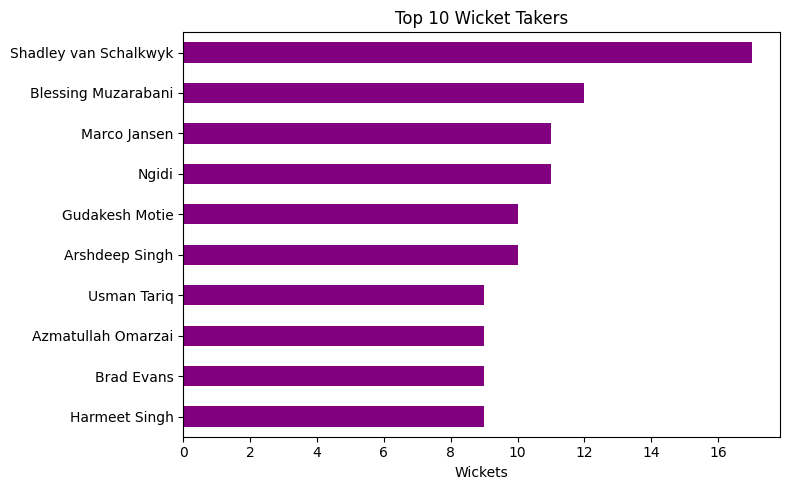

Answer: Shadley van Schalkwyk (USA) – 17 wickets. Economy rate: not available in this dataset.


In [17]:
bowl = (w.groupby('Bowler').agg(Team=('BowlTeam', 'first'), Wickets=('match_id', 'count'), Matches=('match_id', 'nunique'))
          .sort_values(['Wickets', 'Matches'], ascending=[False, True]))
bowl['Wkts_per_match'] = (bowl.Wickets / bowl.Matches).round(2)
q7 = bowl.head(10)
display(q7)

q7['Wickets'][::-1].plot(kind='barh', figsize=(8, 5), color='purple')
plt.title('Top 10 Wicket Takers'); plt.xlabel('Wickets'); plt.ylabel(''); plt.tight_layout(); plt.show()
print(f"Answer: {q7.index[0]} ({q7.Team.iloc[0]}) – {q7.Wickets.iloc[0]} wickets. Economy rate: not available in this dataset.")

## Q8. Runs from boundaries and strike-rate comparison


,Team,Runs,Fours,Sixes,BoundaryRuns,Boundary %,SR
Player,,,,,,,
Sahibzada Farhan,Pakistan,383,37,18,256,66.8,162.98
Suryakumar Yadav,India,265,27,13,186,70.2,151.43
Aiden Markram,South Africa,264,31,10,184,69.7,178.38
Shimron Hetmyer,West Indies,221,15,17,162,73.3,182.64
Brian Bennett,Zimbabwe,277,31,6,160,57.8,135.78
Tim Seifert,New Zealand,216,25,9,154,71.3,157.66
Ryan Rickelton,South Africa,197,17,11,134,68.0,177.48
Finn Allen,New Zealand,189,14,12,128,67.7,173.39
Ishan Kishan,India,157,15,11,126,80.3,172.53


Strike rate of top-10 boundary hitters: 162.1
Strike rate of all other players       : 132.6


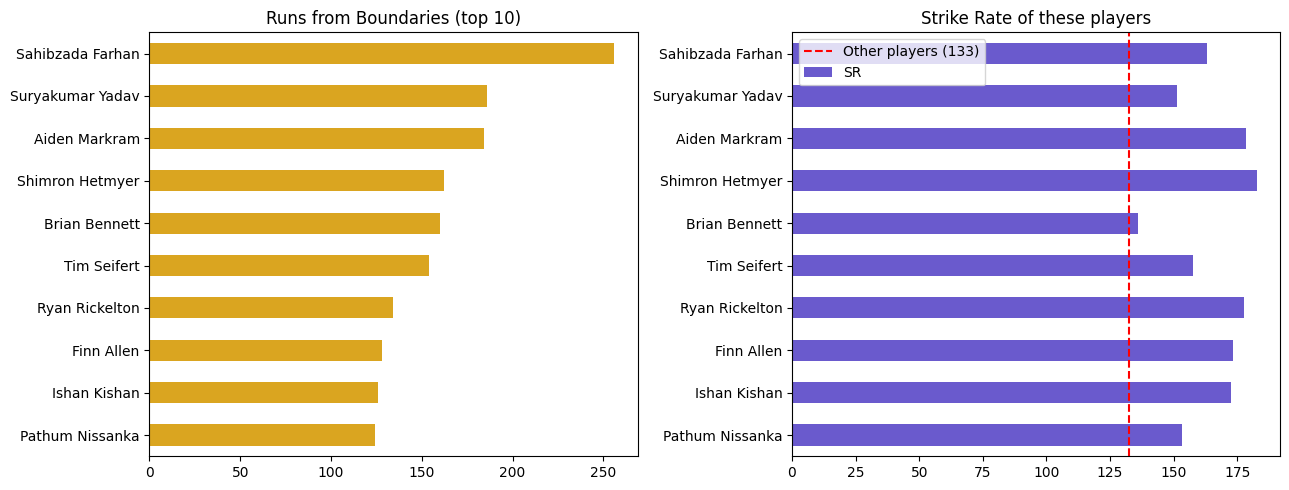

In [18]:
player['BoundaryRuns'] = player.Fours * 4 + player.Sixes * 6
player['Boundary %'] = (player.BoundaryRuns / player.Runs * 100).round(1)

q8 = player.sort_values('BoundaryRuns', ascending=False).head(10)
display(q8[['Team', 'Runs', 'Fours', 'Sixes', 'BoundaryRuns', 'Boundary %', 'SR']])

others = player.drop(q8.index)
sr_top = q8.Runs.sum() / q8.Balls.sum() * 100
sr_oth = others.Runs.sum() / others.Balls.sum() * 100
print(f'Strike rate of top-10 boundary hitters: {sr_top:.1f}')
print(f'Strike rate of all other players       : {sr_oth:.1f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
q8['BoundaryRuns'][::-1].plot(kind='barh', ax=ax[0], color='goldenrod', title='Runs from Boundaries (top 10)')
ax[0].set_ylabel('')
q8['SR'][::-1].plot(kind='barh', ax=ax[1], color='slateblue', title='Strike Rate of these players')
ax[1].axvline(sr_oth, color='red', ls='--', label=f'Other players ({sr_oth:.0f})'); ax[1].legend(); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

## Q9. Player Performance Score (PPS) – top 20 batsmen


,Rank,Team,Runs,Balls,SR,Fours,Sixes,PPS
Player,,,,,,,,
Sahibzada Farhan,1,Pakistan,383,235,162.98,37,18,92.6
Aiden Markram,2,South Africa,264,148,178.38,31,10,68.9
Suryakumar Yadav,3,India,265,175,151.43,27,13,68.2
Shimron Hetmyer,4,West Indies,221,121,182.64,15,17,64.9
Brian Bennett,5,Zimbabwe,277,204,135.78,31,6,64.3
Tim Seifert,6,New Zealand,216,137,157.66,25,9,57.8
Ryan Rickelton,7,South Africa,197,111,177.48,17,11,56.6
Finn Allen,8,New Zealand,189,109,173.39,14,12,55.1
Pavan Rathnayake,9,Sri Lanka,205,132,155.30,20,7,53.0


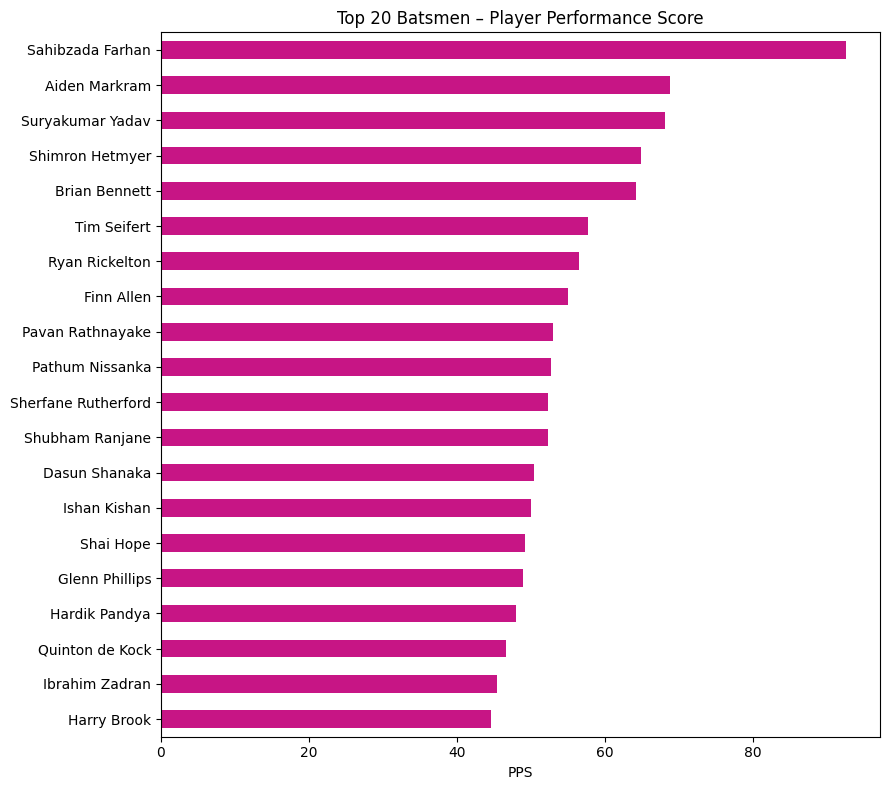

In [19]:
q = player[player.Balls >= 30].copy()
scale = lambda s: (s - s.min()) / (s.max() - s.min()) * 100
q['PPS'] = (0.35 * scale(q.Runs) + 0.25 * scale(q.SR) + 0.15 * scale(q.Sixes)
            + 0.15 * scale(q.Balls) + 0.10 * scale(q.Fours)).round(1)
q9 = q.sort_values('PPS', ascending=False).head(20)
q9.insert(0, 'Rank', range(1, 21))
display(q9[['Rank', 'Team', 'Runs', 'Balls', 'SR', 'Fours', 'Sixes', 'PPS']])

q9['PPS'][::-1].plot(kind='barh', figsize=(9, 8), color='mediumvioletred')
plt.title('Top 20 Batsmen – Player Performance Score'); plt.xlabel('PPS'); plt.ylabel(''); plt.tight_layout(); plt.show()

## Q10. Top 10 all-round performers – Match Impact Score (MIS)


,Rank,Team,Matches,Runs,Wickets,Fours,Sixes,Total_MIS,Avg_MIS
Player,,,,,,,,,
Jason Holder,1,West Indies,6,104.0,8.0,5.0,10.0,354.2,59.0
Rachin Ravindra,2,New Zealand,5,115.0,9.0,9.0,5.0,352.1,70.4
Glenn Phillips,3,New Zealand,6,176.0,3.0,16.0,8.0,328.7,54.8
Hardik Pandya,4,India,6,160.0,3.0,9.0,12.0,326.5,54.4
Shivam Dube,5,India,6,131.0,5.0,6.0,10.0,322.8,53.8
Azmatullah Omarzai,6,Afghanistan,4,89.0,9.0,5.0,6.0,317.9,79.5
Sam Curran,7,England,5,136.0,5.0,7.0,7.0,310.1,62.0
Ben Manenti,8,Italy,4,138.0,5.0,11.0,8.0,294.2,73.6
Dasun Shanaka,9,Sri Lanka,5,135.0,4.0,4.0,13.0,285.0,57.0


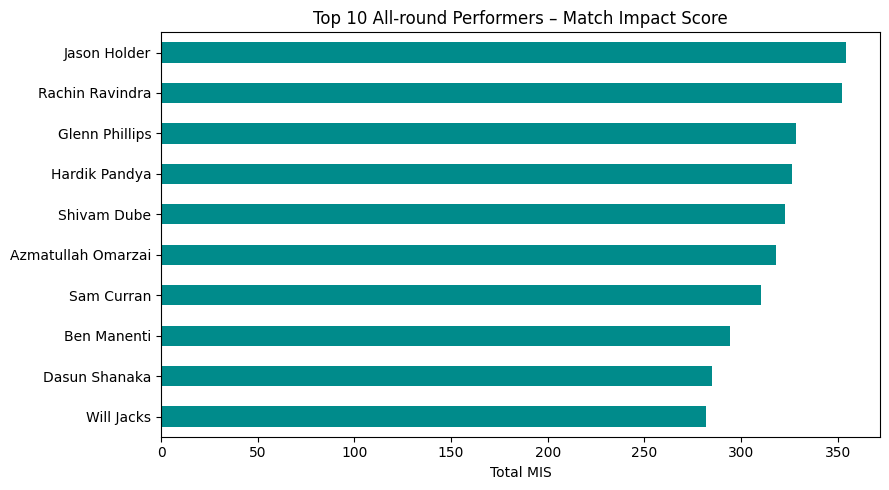

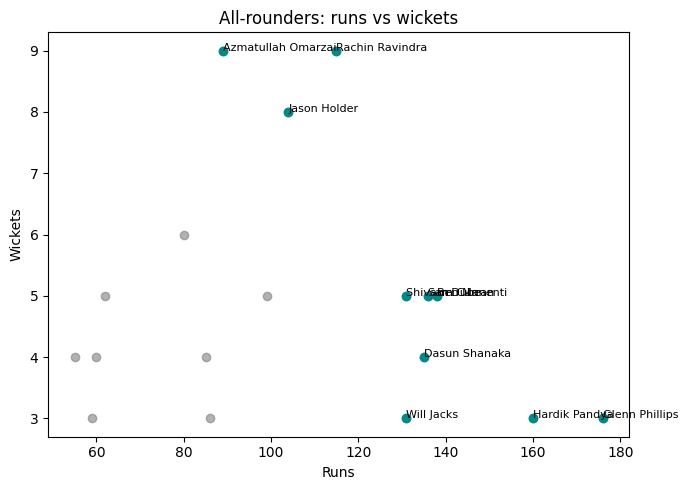

Answer: Jason Holder (West Indies) is the top all-round performer with MIS 354.2.


In [20]:
bat = (df.groupby(['match_id', 'Player'])
         .agg(Team=('Team', 'first'), Runs=('R', 'sum'), Balls=('B', 'sum'), Fours=('4s', 'sum'), Sixes=('6s', 'sum'))
         .reset_index())
wk = (w.groupby(['match_id', 'Bowler']).agg(BowlTeam=('BowlTeam', 'first'), Wickets=('Bowler', 'count'))
        .reset_index().rename(columns={'Bowler': 'Player'}))

mis = bat.merge(wk, on=['match_id', 'Player'], how='outer')
mis['Team'] = mis['Team'].fillna(mis['BowlTeam'])
mis = mis.drop(columns='BowlTeam').fillna(0)

mis['SR'] = np.where(mis.Balls > 0, mis.Runs / mis.Balls * 100, 0)
mis['Win'] = (mis.match_id.map(winner) == mis.Team).astype(int)

sr_bonus = np.where(mis.Balls >= 10, ((mis.SR - 100) / 10).clip(-5, 10), 0)
mis['MIS'] = (mis.Runs + 20 * mis.Wickets + sr_bonus + mis.Fours + 2 * mis.Sixes + 10 * mis.Win).round(1)

ar = (mis.groupby('Player')
         .agg(Team=('Team', 'first'), Matches=('match_id', 'nunique'), Runs=('Runs', 'sum'), Wickets=('Wickets', 'sum'),
              Fours=('Fours', 'sum'), Sixes=('Sixes', 'sum'), Total_MIS=('MIS', 'sum'), Avg_MIS=('MIS', 'mean')))
ar = ar[(ar.Wickets >= 3) & (ar.Runs >= 50) & (ar.index.isin(player.index))]
q10 = ar.sort_values('Total_MIS', ascending=False).head(10).round(1)
q10.insert(0, 'Rank', range(1, len(q10) + 1))
display(q10)

q10['Total_MIS'][::-1].plot(kind='barh', figsize=(9, 5), color='darkcyan')
plt.title('Top 10 All-round Performers – Match Impact Score'); plt.xlabel('Total MIS'); plt.ylabel(''); plt.tight_layout(); plt.show()

# Runs vs wickets for all-rounders
plt.figure(figsize=(7, 5)); plt.scatter(ar.Runs, ar.Wickets, color='gray', alpha=.6)
plt.scatter(q10.Runs, q10.Wickets, color='darkcyan')
for n, r in q10.iterrows(): plt.annotate(n, (r.Runs, r.Wickets), fontsize=8)
plt.xlabel('Runs'); plt.ylabel('Wickets'); plt.title('All-rounders: runs vs wickets'); plt.tight_layout(); plt.show()
print(f"Answer: {q10.index[0]} ({q10.Team.iloc[0]}) is the top all-round performer with MIS {q10.Total_MIS.iloc[0]}.")